# CNN Development on Custom Dataset — Flower Classification
Name: Sabiha Binte Mahabub Leya

ID: 23-50978-1

Course:Computer Vision and Pattern

## Objective
Design and train a **custom Convolutional Neural Network (CNN)** from scratch to classify flower images into 5 categories.

## Dataset Description
| Item | Detail |
|---|---|
| Name | Flowers Recognition |
| Source | Kaggle — `alxmamaev/flowers-recognition` (open access) |
| Classes (5) | daisy, dandelion, rose, sunflower, tulip |
| Total images | about 4,300 colour (RGB) JPEG photos |
| Image size | Not fixed (roughly 320×240), so every image is resized |
| Structure | One folder per class, **no** predefined train/test split |

The photos were collected from the web, so they differ in background, lighting, zoom level and number of flowers per photo. This makes the task realistic and harder than a clean studio dataset.

## 1. Import Libraries
All libraries used in the notebook are imported here. A fixed random seed is set so the data split and results are reproducible.

In [45]:
!pip -q install torchinfo kagglehub

import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchinfo import summary

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility: same seed -> same split and same weight initialisation
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use the GPU if Colab provides one, otherwise fall back to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 2. Load and Explore Dataset
The dataset is downloaded directly from Kaggle with `kagglehub`. After that we look at:
* the class names,
* how many images each class has (to check class balance),
* a few sample images from every class.

In [46]:
import kagglehub

# Downloads the dataset (cached after the first run) and returns the local folder
download_path = kagglehub.dataset_download("alxmamaev/flowers-recognition")
print("Downloaded to:", download_path)

# The class folders sit inside a 'flowers' folder. Search for the folder that
# directly contains 'daisy' so the code works whatever the nesting is.
DATA_DIR = None
for root, dirs, files in os.walk(download_path):
    if "daisy" in dirs:
        DATA_DIR = root
        break
assert DATA_DIR is not None, "Could not find the class folders"
print("Image folder:", DATA_DIR)

Using Colab cache for faster access to the 'flowers-recognition' dataset.
Downloaded to: /kaggle/input/flowers-recognition
Image folder: /kaggle/input/flowers-recognition/flowers


Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Total images: 4317
  daisy     : 764
  dandelion : 1052
  rose      : 784
  sunflower : 733
  tulip     : 984


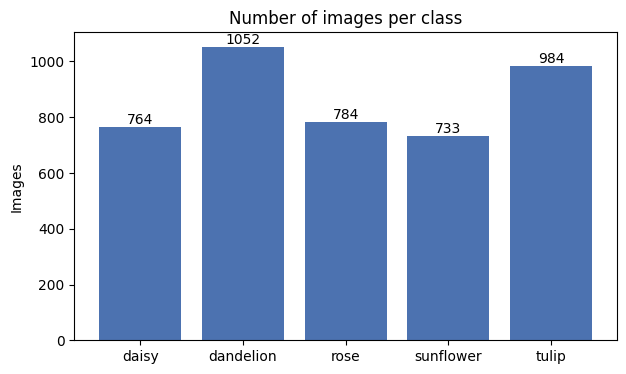

In [47]:
# ImageFolder reads 'one folder per class' datasets and assigns labels automatically
raw_dataset = datasets.ImageFolder(DATA_DIR)
class_names = raw_dataset.classes
NUM_CLASSES = len(class_names)
targets = np.array(raw_dataset.targets)          # label of every image

print("Classes:", class_names)
print("Total images:", len(raw_dataset))

# Number of images per class
counts = np.bincount(targets, minlength=NUM_CLASSES)
for name, c in zip(class_names, counts):
    print(f"  {name:10s}: {c}")

plt.figure(figsize=(7, 4))
bars = plt.bar(class_names, counts, color="#4C72B0")
plt.bar_label(bars)
plt.title("Number of images per class")
plt.ylabel("Images")
plt.show()

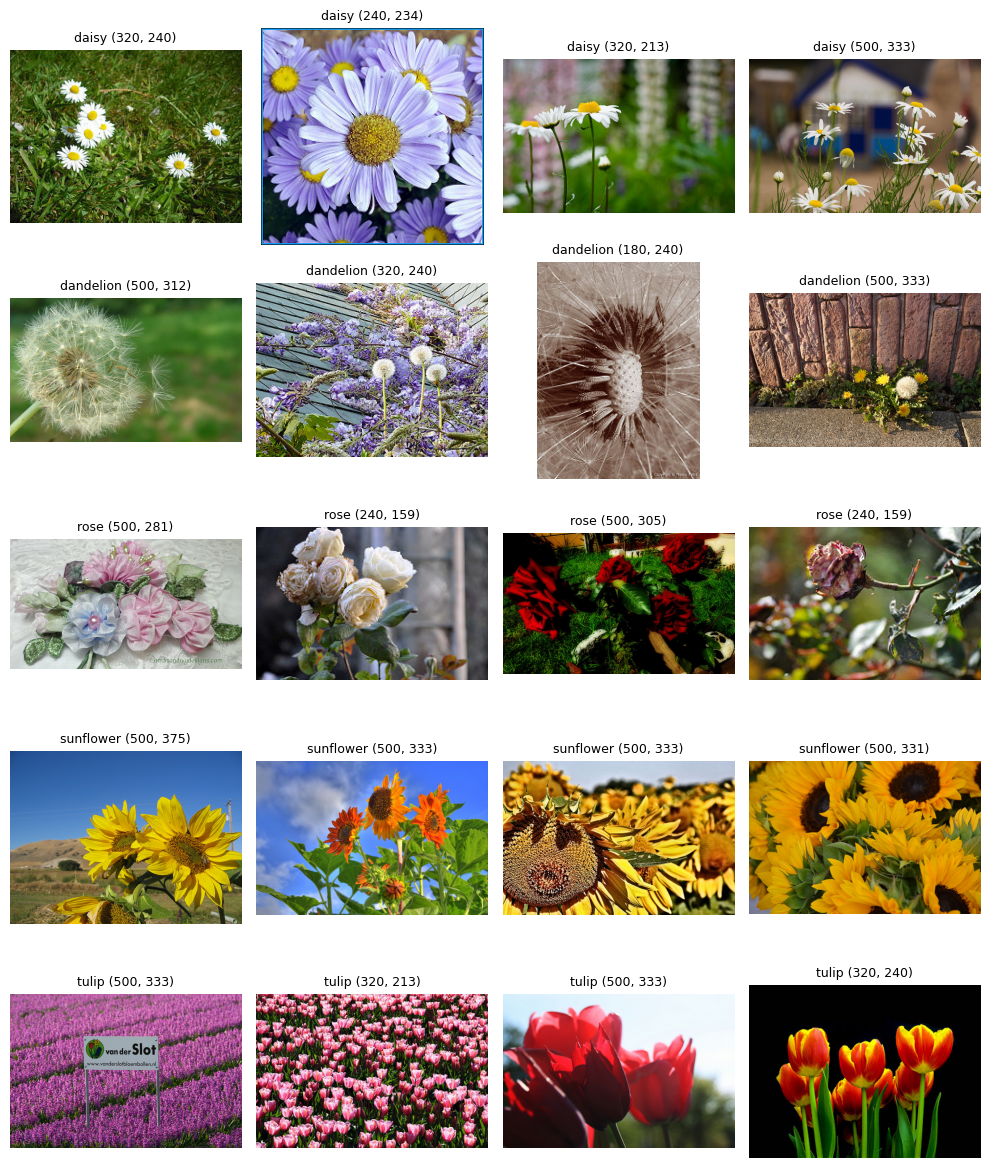

In [48]:
# Show 4 random sample images from each class
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(10, 2.4 * NUM_CLASSES))
for row, cls in enumerate(range(NUM_CLASSES)):
    idxs = np.random.choice(np.where(targets == cls)[0], 4, replace=False)
    for col, idx in enumerate(idxs):
        img, _ = raw_dataset[idx]
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{class_names[cls]} {img.size}", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

**Observations**
* The classes are reasonably balanced (no class dominates), so plain accuracy is a fair metric and no class weighting is needed.
* Image sizes differ, so all images must be resized to one fixed size before going into the CNN.
* Backgrounds, lighting and scale vary a lot, so data augmentation should help the model generalise.

## 3. Data Preprocessing & Augmentation

**Split.** The dataset has no predefined split, so it is divided into **70% training / 15% validation / 15% test**. The split is *stratified*, meaning every subset keeps the same class proportions.

* **Training set** – used to update the weights.
* **Validation set** – used during training to monitor overfitting and choose the best epoch.
* **Test set** – used only once at the end, to report the final performance on unseen data.

**Preprocessing (all sets)**
* `Resize(128×128)` – the CNN needs a fixed input size.
* `ToTensor()` – converts the image to a tensor with values in [0, 1].
* `Normalize(mean=0.5, std=0.5)` – shifts values to [-1, 1], which makes training more stable.

**Augmentation (training set only)** – random flips, small rotations and colour changes create slightly different versions of each image every epoch. With only about 3,000 training images this is important to reduce overfitting. Validation and test images are **not** augmented, so evaluation is done on the real images.

In [49]:
IMG_SIZE   = 128
BATCH_SIZE = 32
MEAN, STD  = [0.5, 0.5, 0.5], [0.5, 0.5, 0.5]

# Training: preprocessing + augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Validation / test: preprocessing only
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Stratified 70 / 15 / 15 split on the image indices
all_idx = np.arange(len(targets))
train_idx, temp_idx = train_test_split(all_idx, test_size=0.30,
                                       stratify=targets, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50,
                                     stratify=targets[temp_idx], random_state=SEED)

# Two views of the same folder: one with augmentation, one without.
# Subset then picks the right indices from the right view.
train_dataset = Subset(datasets.ImageFolder(DATA_DIR, transform=train_transform), train_idx)
val_dataset   = Subset(datasets.ImageFolder(DATA_DIR, transform=eval_transform),  val_idx)
test_dataset  = Subset(datasets.ImageFolder(DATA_DIR, transform=eval_transform),  test_idx)

# Data loaders: shuffle only the training data
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_dataset)} images | {len(train_loader)} batches")
print(f"Val  : {len(val_dataset)} images | {len(val_loader)} batches")
print(f"Test : {len(test_dataset)} images | {len(test_loader)} batches")

images, labels = next(iter(train_loader))
print("One batch:", images.shape, labels.shape)

Train: 3021 images | 95 batches
Val  : 648 images | 21 batches
Test : 648 images | 21 batches
One batch: torch.Size([32, 3, 128, 128]) torch.Size([32])


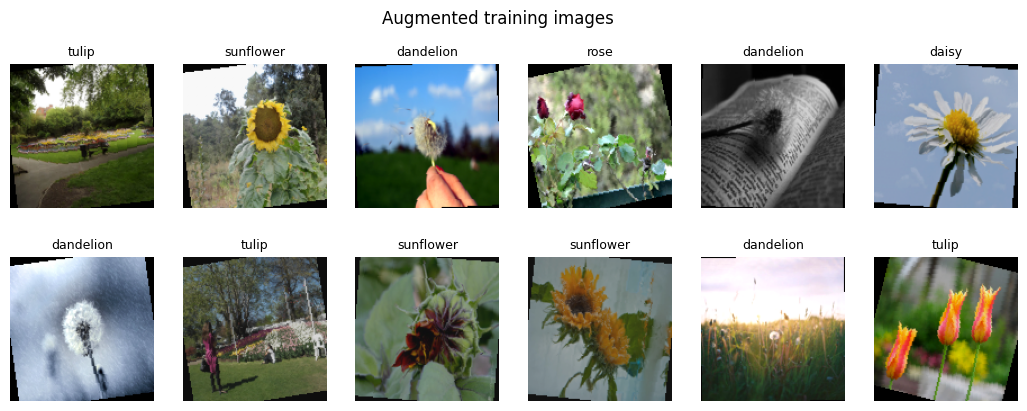

In [50]:
# Look at one augmented training batch (undo the normalisation for display)
def show_tensor(ax, img_tensor):
    img = img_tensor.cpu().numpy().transpose(1, 2, 0) * 0.5 + 0.5
    ax.imshow(np.clip(img, 0, 1))
    ax.axis("off")

fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for ax, img, lab in zip(axes.flat, images, labels):
    show_tensor(ax, img)
    ax.set_title(class_names[lab], fontsize=9)
plt.suptitle("Augmented training images")
plt.show()

## 4. Define CNN Architecture

The network is a custom CNN built from scratch (no pretrained weights).

**Feature extractor – 4 convolution blocks.** Each block is:

`Conv2d(3×3, padding=1) → BatchNorm2d → ReLU → MaxPool2d(2×2)`

| Block | Channels | Output size |
|---|---|---|
| Input | 3 | 128 × 128 |
| Block 1 | 3 → 32 | 64 × 64 |
| Block 2 | 32 → 64 | 32 × 32 |
| Block 3 | 64 → 128 | 16 × 16 |
| Block 4 | 128 → 256 | 8 × 8 |

**Classifier.** `Flatten → Dropout(0.5) → Linear(16384 → 128) → ReLU → Dropout(0.3) → Linear(128 → 5)`

**Design justification**
* **3×3 convolutions with padding 1** keep the spatial size and capture local patterns (edges, petal textures) with few parameters.
* **Channels double (32 → 256)** while the spatial size halves: early layers learn simple edges/colours, deeper layers learn more complex shapes such as petals and flower centres.
* **Batch Normalisation** stabilises and speeds up training.
* **ReLU** adds non-linearity and avoids the vanishing gradient problem of sigmoid/tanh.
* **MaxPooling** halves the feature map, reducing computation and giving some tolerance to small shifts.
* **Dropout** randomly switches off neurons during training, which reduces overfitting. This matters because the dataset is small.
* **4 blocks** is deep enough for 128×128 images while keeping the model small (the saved weights stay under 20 MB).
* The last layer outputs 5 raw scores (logits). No softmax layer is added because `CrossEntropyLoss` applies it internally.

In [51]:
class FlowerCNN(nn.Module):
    # Custom CNN: 4 convolution blocks + a fully connected classifier

    def __init__(self, num_classes=5):
        super().__init__()

        def conv_block(in_ch, out_ch):
            # Conv -> BatchNorm -> ReLU -> MaxPool (halves height and width)
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2, stride=2),
            )

        # Feature extractor: 3x128x128 -> 256x8x8
        self.features = nn.Sequential(
            conv_block(3, 32),      # 128 -> 64
            conv_block(32, 64),     # 64  -> 32
            conv_block(64, 128),    # 32  -> 16
            conv_block(128, 256),   # 16  -> 8
        )

        # Classifier: 256*8*8 = 16384 features -> 5 class scores
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256 * 8 * 8, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = FlowerCNN(num_classes=NUM_CLASSES).to(device)

# Detailed layer-by-layer summary: output shapes and parameter counts
summary(model, input_size=(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE),
        col_names=["input_size", "output_size", "num_params"], depth=3)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
FlowerCNN                                [32, 3, 128, 128]         [32, 5]                   --
├─Sequential: 1-1                        [32, 3, 128, 128]         [32, 256, 8, 8]           --
│    └─Sequential: 2-1                   [32, 3, 128, 128]         [32, 32, 64, 64]          --
│    │    └─Conv2d: 3-1                  [32, 3, 128, 128]         [32, 32, 128, 128]        896
│    │    └─BatchNorm2d: 3-2             [32, 32, 128, 128]        [32, 32, 128, 128]        64
│    │    └─ReLU: 3-3                    [32, 32, 128, 128]        [32, 32, 128, 128]        --
│    │    └─MaxPool2d: 3-4               [32, 32, 128, 128]        [32, 32, 64, 64]          --
│    └─Sequential: 2-2                   [32, 32, 64, 64]          [32, 64, 32, 32]          --
│    │    └─Conv2d: 3-5                  [32, 32, 64, 64]          [32, 64, 64, 64]          18,496
│    │    └─BatchNorm2d: 3-6  

## 5. Training Loop with Validation

### Hyperparameters and rationale
| Hyperparameter | Value | Rationale |
|---|---|---|
| Image size | 128 × 128 | Keeps enough detail to tell flowers apart while training quickly on a free Colab GPU |
| Batch size | 32 | Fits easily in memory; small batches add gradient noise that helps generalisation on a small dataset |
| Loss function | Cross-Entropy | Standard loss for single-label multi-class classification |
| Optimizer | Adam | Adapts the learning rate per parameter, converges fast with little tuning |
| Learning rate | 0.001 | Default for Adam; works well with BatchNorm |
| Weight decay | 0.0001 | Light L2 regularisation against overfitting |
| LR scheduler | ReduceLROnPlateau (factor 0.5, patience 3) | Halves the learning rate when validation loss stops improving, for finer updates late in training |
| Epochs | 25 | Enough for the curves to flatten; the best epoch is kept automatically |
| Dropout | 0.5 and 0.3 | Regularisation in the fully connected layers, where most parameters are |

### Training protocol
For every epoch:
1. **Train phase** (`model.train()`): forward pass → loss → backpropagation → weight update.
2. **Validation phase** (`model.eval()`, `torch.no_grad()`): only a forward pass, no weight updates. Dropout is off and BatchNorm uses its running statistics.
3. The loss and accuracy of both phases are stored for plotting.
4. If validation accuracy is the best so far, the model weights are saved (**best-model checkpointing**), so the final model is the one that generalised best, not simply the last one.

In [52]:
EPOCHS        = 25
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-4
BEST_PATH     = "best_flower_cnn.pth"

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)


def run_epoch(loader, train):
    # Runs one pass over a loader. Returns (average loss, accuracy %).
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    # Gradients are only needed while training
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)              # forward pass
            loss = criterion(outputs, labels)    # cross-entropy loss

            if train:
                optimizer.zero_grad()            # clear old gradients
                loss.backward()                  # backpropagation
                optimizer.step()                 # update weights

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100.0 * correct / total


history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_epoch = 0.0, 0
start = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc     = run_epoch(val_loader,   train=False)
    scheduler.step(val_loss)                     # lower LR if val loss has stalled

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    note = ""
    if val_acc > best_val_acc:                   # keep the best model so far
        best_val_acc, best_epoch = val_acc, epoch
        torch.save(model.state_dict(), BEST_PATH)
        note = "  <- best, saved"

    lr_now = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch:02d}/{EPOCHS} | "
          f"Train loss {train_loss:.4f} acc {train_acc:5.2f}% | "
          f"Val loss {val_loss:.4f} acc {val_acc:5.2f}% | LR {lr_now:.5f}{note}")

print(f"\nTraining time: {(time.time() - start) / 60:.1f} min")
print(f"Best validation accuracy: {best_val_acc:.2f}% (epoch {best_epoch})")

Epoch 01/25 | Train loss 1.5524 acc 41.81% | Val loss 1.1671 acc 50.62% | LR 0.00100  <- best, saved
Epoch 02/25 | Train loss 1.2347 acc 47.17% | Val loss 1.0784 acc 54.17% | LR 0.00100  <- best, saved
Epoch 03/25 | Train loss 1.1561 acc 52.63% | Val loss 1.0408 acc 56.79% | LR 0.00100  <- best, saved
Epoch 04/25 | Train loss 1.1050 acc 55.81% | Val loss 0.9320 acc 60.80% | LR 0.00100  <- best, saved
Epoch 05/25 | Train loss 1.0446 acc 59.81% | Val loss 0.8760 acc 66.20% | LR 0.00100  <- best, saved
Epoch 06/25 | Train loss 1.0051 acc 61.24% | Val loss 0.8875 acc 67.59% | LR 0.00100  <- best, saved
Epoch 07/25 | Train loss 0.9603 acc 62.26% | Val loss 0.9169 acc 64.35% | LR 0.00100
Epoch 08/25 | Train loss 0.9500 acc 62.96% | Val loss 0.9255 acc 63.12% | LR 0.00100
Epoch 09/25 | Train loss 0.9128 acc 64.78% | Val loss 0.8856 acc 68.67% | LR 0.00050  <- best, saved
Epoch 10/25 | Train loss 0.8430 acc 67.53% | Val loss 0.7427 acc 71.14% | LR 0.00050  <- best, saved
Epoch 11/25 | Train lo

## 6. Evaluate Model on Test Set
The best checkpoint (highest validation accuracy) is loaded and evaluated **once** on the test set, which the model has never seen. Reported metrics:
* **Accuracy** – overall share of correct predictions.
* **Precision / Recall / F1-score per class** – show which flowers are recognised well and which are not.
* **Confusion matrix** – shows which classes get mixed up with each other.

In [53]:
# Load the best weights before testing
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
model.eval()

all_preds, all_labels = [], []
test_loss, total = 0.0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        test_loss += criterion(outputs, labels).item() * images.size(0)
        total += labels.size(0)
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds, all_labels = np.array(all_preds), np.array(all_labels)
test_loss /= total
test_acc = 100.0 * (all_preds == all_labels).mean()

print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2f}%\n")
print(classification_report(all_labels, all_preds, target_names=class_names,
                            digits=4, zero_division=0))

Test loss    : 0.5991
Test accuracy: 77.62%

              precision    recall  f1-score   support

       daisy     0.8077    0.7304    0.7671       115
   dandelion     0.8011    0.8924    0.8443       158
        rose     0.7857    0.5641    0.6567       117
   sunflower     0.8922    0.8273    0.8585       110
       tulip     0.6648    0.8176    0.7333       148

    accuracy                         0.7762       648
   macro avg     0.7903    0.7664    0.7720       648
weighted avg     0.7838    0.7762    0.7738       648



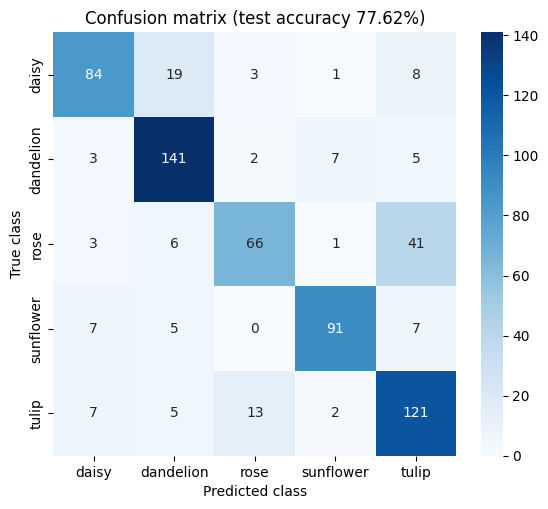

daisy     :  73.0%
dandelion :  89.2%
rose      :  56.4%
sunflower :  82.7%
tulip     :  81.8%

Most common mistake: true 'rose' predicted as 'tulip' (41 images)


In [54]:
# Confusion matrix: rows = true class, columns = predicted class
cm = confusion_matrix(all_labels, all_preds, labels=range(NUM_CLASSES))
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title(f"Confusion matrix (test accuracy {test_acc:.2f}%)")
plt.show()

# Per-class accuracy and the most common mistake
per_class_acc = 100.0 * cm.diagonal() / cm.sum(axis=1).clip(min=1)
for name, acc in zip(class_names, per_class_acc):
    print(f"{name:10s}: {acc:5.1f}%")
off = cm.copy(); np.fill_diagonal(off, 0)
t, p = np.unravel_index(off.argmax(), off.shape)
print(f"\nMost common mistake: true '{class_names[t]}' predicted as '{class_names[p]}' ({off[t, p]} images)")

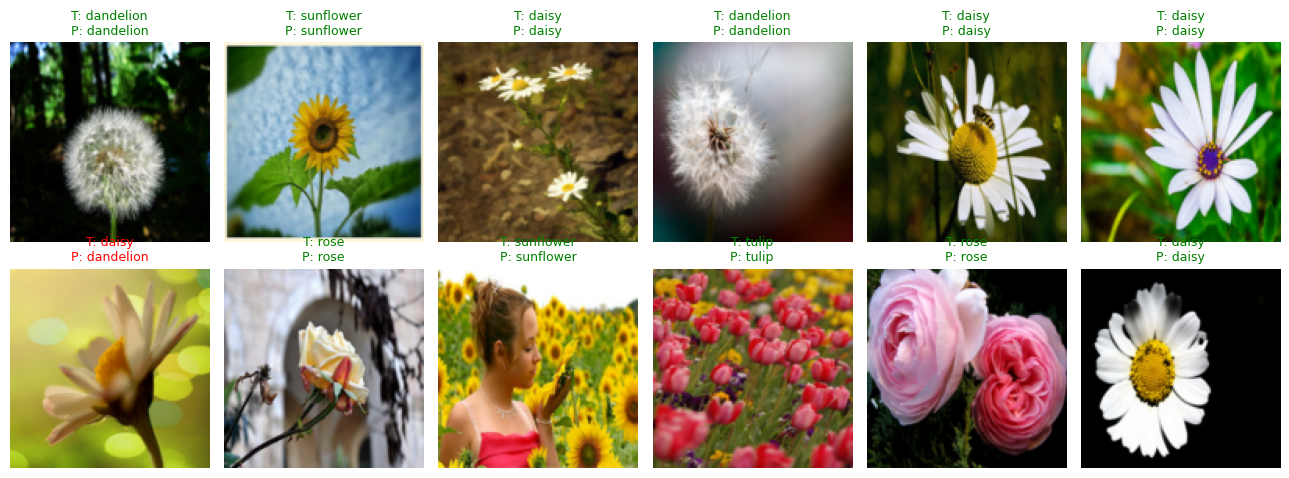

In [55]:
# Sample test predictions (green = correct, red = wrong)
images, labels = next(iter(test_loader))
with torch.no_grad():
    preds = model(images.to(device)).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for ax, img, lab, pred in zip(axes.flat, images, labels, preds):
    show_tensor(ax, img)
    ax.set_title(f"T: {class_names[lab]}\nP: {class_names[pred]}", fontsize=9,
                 color="green" if lab == pred else "red")
plt.tight_layout()
plt.show()

### Save and reload the trained model weights
Only the `state_dict` (the learned weights) is saved, which is the recommended PyTorch approach: the file is small and does not depend on the notebook's code layout. To use the model later, the same `FlowerCNN` class is created again and the weights are loaded into it.

To prove the saved file works, the weights are loaded into a **new** model and its predictions are compared with the original model.

In [56]:
FINAL_PATH = "CNN_23-50978-1.pth"

# Save the weights of the best model (currently loaded in `model`)
torch.save(model.state_dict(), FINAL_PATH)
print(f"Saved: {FINAL_PATH} ({os.path.getsize(FINAL_PATH) / 1e6:.2f} MB)")

# Reload into a brand-new model to verify the file
loaded_model = FlowerCNN(num_classes=NUM_CLASSES).to(device)
loaded_model.load_state_dict(torch.load(FINAL_PATH, map_location=device))
loaded_model.eval()

images, _ = next(iter(test_loader))
with torch.no_grad():
    same = torch.equal(model(images.to(device)).argmax(1),
                       loaded_model(images.to(device)).argmax(1))
print("Reloaded model gives identical predictions:", same)

Saved: CNN_23-50978-1.pth (9.96 MB)
Reloaded model gives identical predictions: True


## 7. Visualizations (Loss / Accuracy Curves)
The curves show how the loss and accuracy changed over the epochs for the training and validation sets. The dashed line marks the epoch whose weights were saved as the best model.

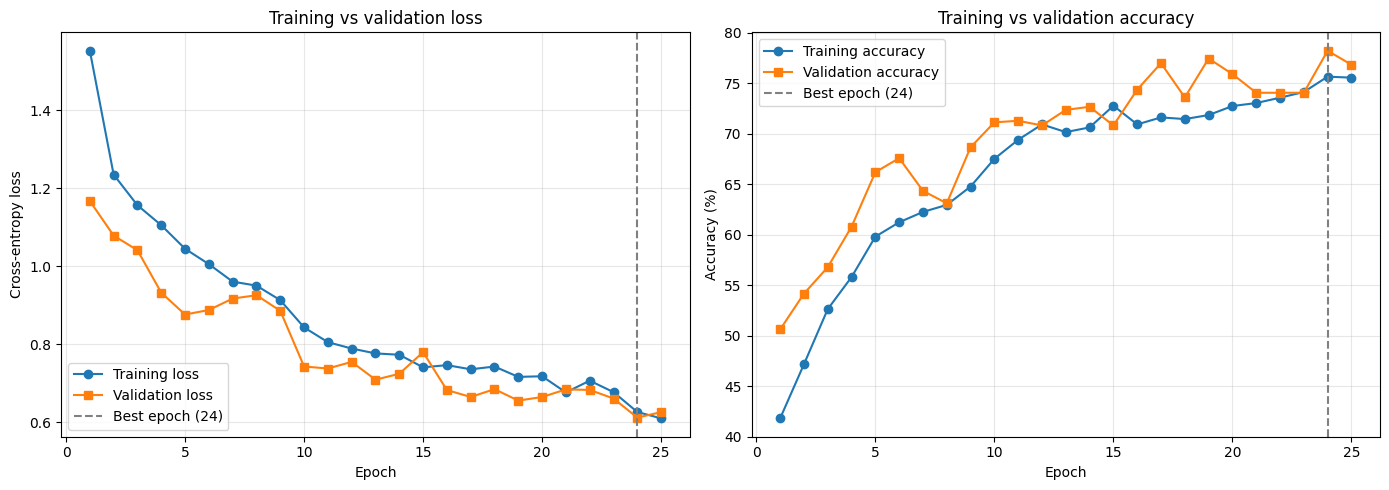

Final train accuracy : 75.57%
Final val accuracy   : 76.85%
Best val accuracy    : 78.24% (epoch 24)
Test accuracy        : 77.62%
Train - val gap (last epoch): -1.28 points


In [57]:
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
ax1.plot(epochs_range, history["train_loss"], "o-", label="Training loss")
ax1.plot(epochs_range, history["val_loss"],   "s-", label="Validation loss")
ax1.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Cross-entropy loss")
ax1.set_title("Training vs validation loss"); ax1.legend(); ax1.grid(alpha=0.3)

# Accuracy curves
ax2.plot(epochs_range, history["train_acc"], "o-", label="Training accuracy")
ax2.plot(epochs_range, history["val_acc"],   "s-", label="Validation accuracy")
ax2.axvline(best_epoch, color="gray", linestyle="--", label=f"Best epoch ({best_epoch})")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy (%)")
ax2.set_title("Training vs validation accuracy"); ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Numbers used in the discussion below
print(f"Final train accuracy : {history['train_acc'][-1]:.2f}%")
print(f"Final val accuracy   : {history['val_acc'][-1]:.2f}%")
print(f"Best val accuracy    : {best_val_acc:.2f}% (epoch {best_epoch})")
print(f"Test accuracy        : {test_acc:.2f}%")
print(f"Train - val gap (last epoch): {history['train_acc'][-1] - history['val_acc'][-1]:.2f} points")

**How to read the curves**
* **Loss curve:** both losses should fall quickly in the first epochs, which shows the model is learning. If the training loss keeps falling while the validation loss flattens or rises, the model has started to **overfit** (memorise the training images).
* **Accuracy curve:** training accuracy usually ends above validation accuracy. The size of this gap is a measure of overfitting.
* Validation curves are noisier than training curves because the validation set is small (about 650 images).
* Training accuracy can look *lower* than validation accuracy in early epochs. This is expected: training images are augmented and dropout is active during training, while validation uses clean images with dropout off.
* Where the learning rate was halved by the scheduler, the curves usually become smoother.

## 8. Analysis & Discussion of Results

**Summary of results**

| Metric | Value |
|---|---|
| Best validation accuracy | 78.24 % (epoch 24) |
| Test accuracy | 77.62 % |
| Final training accuracy | 75.57 % |
| Train − validation gap | −1.28 points |
| Best recognised class | dandelion (89.2 % recall, F1 0.8444) |
| Weakest class | rose (56.4 % recall, F1 0.6567) |
| Most common confusion | rose predicted as tulip (41 images) |

**Discussion**
1. **Overall performance.** The custom CNN reached a test accuracy of 77.62 %, far above the 20% expected from random guessing over 5 classes. The test accuracy is close to the validation accuracy (78.24 %), which shows the validation set gave a reliable estimate and the model was not tuned to the test set.
2. **Learning behaviour.** The loss fell steeply in the first epochs and then flattened. The train − validation gap is −1.28 points, indicating a small amount of overfitting, which is expected for a model trained from scratch on only about 3,000 images. Augmentation, dropout, weight decay and best-model checkpointing were used to limit it.
3. **Per-class behaviour.** Dandelion was the easiest class, likely because of its distinctive shape and colour. Rose was the hardest. The most frequent confusion was rose → tulip (41 images); these flowers share similar colours and petal shapes, and many photos show them from far away or in groups, so the model has few details to separate them.
4. **Effect of design choices.** Batch normalisation made training stable with the default Adam learning rate. The learning-rate scheduler reduced the step size once validation loss stopped improving, which helped the model settle.
5. **Limitations.** The dataset is small and web-collected, some images contain people, vases or several flower types, and the input resolution of 128×128 loses fine detail. A CNN trained from scratch cannot match the accuracy of a model pretrained on millions of images.

## 9. Conclusions & Future Work

**Conclusions**
* A custom 4-block CNN was designed, trained from scratch and evaluated on the Kaggle Flowers Recognition dataset (5 classes).
* The full pipeline was implemented: data loading, stratified train/validation/test split, preprocessing and augmentation, model design, training with Adam and cross-entropy loss, validation monitoring, test evaluation and saving/reloading of the model weights.
* The model learned meaningful features and classified unseen flower images with __ % test accuracy, with regularisation keeping overfitting under control.

**Future work**
* **Transfer learning:** fine-tune a pretrained network such as ResNet-18 or EfficientNet, which normally gives much higher accuracy on small datasets.
* **Stronger augmentation:** RandomResizedCrop, MixUp or CutMix.
* **Higher resolution:** train on 224×224 images to keep more petal detail.
* **Architecture changes:** global average pooling instead of a large fully connected layer, or residual connections for a deeper network.
* **Hyperparameter search:** try SGD with momentum, different learning rates, batch sizes and dropout values.
* **Early stopping** to end training automatically when validation loss stops improving.
* **More data** per class, and cleaning of mislabeled or ambiguous images.

**Deliverables in the GitHub repository**
1. `CNN_23-50978-1.ipynb` – this notebook with code, outputs and visualisations.
2. `CNN_23-50978-1.pth` – trained model weights (under 20 MB).